In [49]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.11/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.11/site-packages', '../CRLDenv/lib/python3.11/site-packages', '/home/bergerot/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python311.zip', '/usr/lib/python3.11', '/usr/lib/python3.11/lib-dynload', '', '/usr/local/lib/python3.11/dist-packages', '/usr/lib/python3/dist-packages', '/usr/lib/python3.11/dist-packages']


In [50]:
import numpy as np
from scipy.stats import norm

import jax.numpy as jnp
from jax import jit
from functools import partial

from pyCRLD.Agents.Base import abase
from pyCRLD.Utils.Helpers import *

import pandas as pd
import seaborn as sns

In [51]:
from pyCRLD.Agents.StrategyActorCritic import stratAC
from pyCRLD.Environments.EcologicalPublicGood import EcologicalPublicGood
from pyCRLD.Utils import FlowPlot as fp

import numpy as np
import itertools as it
import matplotlib.pyplot as plt
from pyCRLD.Utils.Helpers import compute_stationarydistribution

from datetime import datetime

In [52]:
from DistBase import distbase

In [53]:
# Define environment
env = EcologicalPublicGood(N=2, f=1.2, c=5, m=-4, qc=0.2, qr=0.1, degraded_choice=True)
env

EcologicalPublicGood_2_1.2_5_-4_0.2_0.1_DegChoi

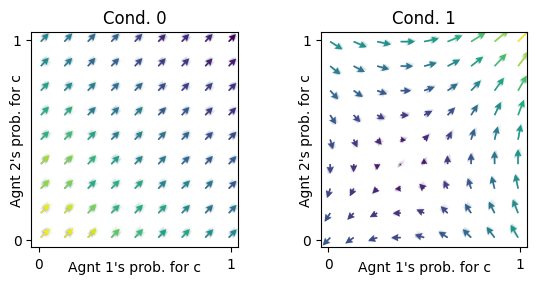

In [54]:
# Init enviornment and MultiAgentEnvironment-interface
mae = stratAC(env=env, learning_rates=0.1, discount_factors=0.9, use_prefactor=True)

x = ([0], [0,1], [0])  # Plotting only the prosperous state
y = ([1], [0,1], [0])  # Plotting only the prosperous state
ax = fp.plot_strategy_flow(mae, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16)

In [55]:
diagonal = np.linspace(0, 1, 101)
diagonal[0] = 0.001
diagonal[100] = 0.999
diagonal

array([0.001, 0.01 , 0.02 , 0.03 , 0.04 , 0.05 , 0.06 , 0.07 , 0.08 ,
       0.09 , 0.1  , 0.11 , 0.12 , 0.13 , 0.14 , 0.15 , 0.16 , 0.17 ,
       0.18 , 0.19 , 0.2  , 0.21 , 0.22 , 0.23 , 0.24 , 0.25 , 0.26 ,
       0.27 , 0.28 , 0.29 , 0.3  , 0.31 , 0.32 , 0.33 , 0.34 , 0.35 ,
       0.36 , 0.37 , 0.38 , 0.39 , 0.4  , 0.41 , 0.42 , 0.43 , 0.44 ,
       0.45 , 0.46 , 0.47 , 0.48 , 0.49 , 0.5  , 0.51 , 0.52 , 0.53 ,
       0.54 , 0.55 , 0.56 , 0.57 , 0.58 , 0.59 , 0.6  , 0.61 , 0.62 ,
       0.63 , 0.64 , 0.65 , 0.66 , 0.67 , 0.68 , 0.69 , 0.7  , 0.71 ,
       0.72 , 0.73 , 0.74 , 0.75 , 0.76 , 0.77 , 0.78 , 0.79 , 0.8  ,
       0.81 , 0.82 , 0.83 , 0.84 , 0.85 , 0.86 , 0.87 , 0.88 , 0.89 ,
       0.9  , 0.91 , 0.92 , 0.93 , 0.94 , 0.95 , 0.96 , 0.97 , 0.98 ,
       0.99 , 0.999])

In [56]:
xinds = (0, 0, 0)
yinds = (1, 0, 0)
S = fp._strategies(mae, xinds, yinds, 0.7, 0.3, 5)
S[0][1, :, :]

array([[0.3       , 0.7       ],
       [0.49009806, 0.50990194]])

In [57]:
def compute_error(s, bin_nr, nr_random, diagonal, sigma, lr, gamma):
    errors = np.zeros((len(diagonal)))
    db = distbase(env, nr_reward_bins=bin_nr, 
                  discretization_sigma=sigma, learning_rates=lr, discount_factors=gamma)
    xinds = (0, s, 0)
    yinds = (1, s, 0)
    for i, val in enumerate(diagonal):
        strats = fp._strategies(db, xinds, yinds, val, val, nr_random)
        err_strats = np.zeros((nr_random))
        for j, x in enumerate(strats):
            distRPE = db.TDerror(x, norm=True)
            detRPE = mae.TDerror(x, norm=True)
            err_strats[j] = np.linalg.norm(detRPE[:,s,:]-distRPE[:,s,:])  # error in degraded env
        errors[i] = np.mean(err_strats)
    return errors

In [58]:
errors01 = compute_error(1, 29, 16, diagonal, 0.1, 0.1, 0.9)

In [59]:
errors06 = compute_error(1, 29, 16, diagonal, 0.6, 0.1, 0.9)

In [60]:
cumulative_error01 = np.sum(errors01)
cumulative_error06 = np.sum(errors06)

In [61]:
cumulative_error01, cumulative_error06

(2.400888636475429, 4.076733558671549)

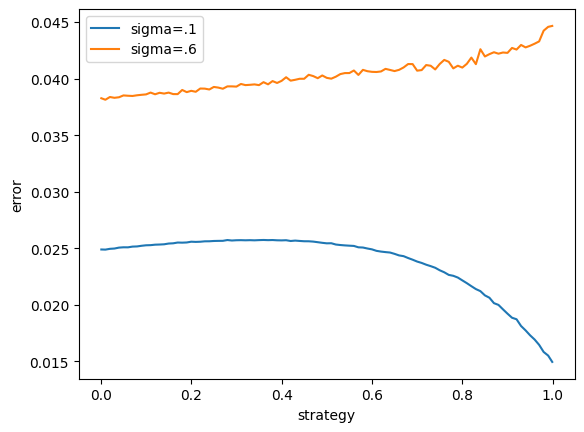

In [62]:
plt.figure()
plt.plot(diagonal, errors01, label="sigma=.1")
plt.plot(diagonal, errors06, label="sigma=.6")
plt.ylabel("error")
plt.xlabel("strategy")
plt.legend()
plt.show()

In [44]:
diagonal2 = np.linspace(0, 1, 11)
diagonal2[0] = 0.001
diagonal2[-1] = 0.999
diagonal2

array([0.001, 0.1  , 0.2  , 0.3  , 0.4  , 0.5  , 0.6  , 0.7  , 0.8  ,
       0.9  , 0.999])

In [45]:
errors01_sparse = compute_error(1, 29, 16, diagonal2, 0.1, 0.1, 0.9)

In [46]:
errors06_sparse = compute_error(1, 29, 16, diagonal2, 0.6, 0.1, 0.9)

In [47]:
np.sum(errors01_sparse), np.sum(errors06_sparse)

(0.8318738889065571, 0.734367348253727)